#Preparation

## Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Import Relevant Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import requests
from google.colab import userdata
import os
from scipy import stats
from scipy.stats import chi2_contingency
from itertools import combinations

# Data Preparation

## Read Data from Gdrive


In [ ]:
path = "/content/drive/MyDrive/SMU Masters/1. Y1 Aug/Statistics for Data Science [DS607]/Project/census_import.csv"
df = pd.read_csv(path)

df["time"] = pd.to_datetime(df["time"])
print(df.round(2))


      Unnamed: 0  I_COMMODITY  \
0              0           95   
1              1           96   
2              2           97   
3              3           98   
4              4           99   
...          ...          ...   
3719        3719           75   
3720        3720           76   
3721        3721           78   
3722        3722           79   
3723        3723           80   

                                      I_COMMODITY_SDESC  GEN_VAL_MO  \
0     TOYS, GAMES & SPORT EQUIPMENT; PARTS & ACCESSO...  4348927943   
1                   MISCELLANEOUS MANUFACTURED ARTICLES   680385884   
2         WORKS OF ART, COLLECTORS' PIECES AND ANTIQUES   485110918   
3              SPECIAL CLASSIFICATION PROVISIONS, NESOI  8139071366   
4                      SPECIAL IMPORT PROVISIONS, NESOI  1902703841   
...                                                 ...         ...   
3719                        NICKEL AND ARTICLES THEREOF   315613194   
3720                      ALUMINUM 

# Data Visualisation

In [ ]:
# Data preview
display(df.head())


,Unnamed: 0,I_COMMODITY,I_COMMODITY_SDESC,GEN_VAL_MO,CON_VAL_MO,DUT_VAL_MO,CAL_DUT_MO,time
0,0,95,"TOYS, GAMES & SPORT EQUIPMENT; PARTS & ACCESSO...",4348927943,4358899170,540166238,36655738,2023-07-01
1,1,96,MISCELLANEOUS MANUFACTURED ARTICLES,680385884,683744270,428998178,31730997,2023-07-01
2,2,97,"WORKS OF ART, COLLECTORS' PIECES AND ANTIQUES",485110918,485135518,16783649,752072,2023-07-01
3,3,98,"SPECIAL CLASSIFICATION PROVISIONS, NESOI",8139071366,8134818130,264232436,782275,2023-07-01
4,4,99,"SPECIAL IMPORT PROVISIONS, NESOI",1902703841,1902703841,1902703841,0,2023-07-01


## Descriptive Statistics

In [ ]:
df_viz = df.copy()

# Remove the automatically generated index column, if present
df_viz = df_viz.drop(columns=["Unnamed: 0"], errors="ignore")

df_viz["time"] = pd.to_datetime(df_viz["time"], errors="coerce")

numeric_cols = [
    "I_COMMODITY",
    "GEN_VAL_MO",
    "CON_VAL_MO",
    "DUT_VAL_MO",
    "CAL_DUT_MO"
]

for col in numeric_cols:
    df_viz[col] = pd.to_numeric(df_viz[col], errors="coerce")
df_viz = df_viz[
    (df_viz["CON_VAL_MO"] > 0) &
    (df_viz["CAL_DUT_MO"] >= 0)
].copy()


# Realized duty rate, expressed as a percentage
df_viz["duty_rate"] = (df_viz["CAL_DUT_MO"] / df_viz["CON_VAL_MO"]) * 100

# Alternative rate for sensitivity analysis
df_viz["duty_rate_general"] = (df_viz["CAL_DUT_MO"] / df_viz["GEN_VAL_MO"].replace(0, np.nan)) * 100

df_viz = df_viz.sort_values(["I_COMMODITY", "time"]).reset_index(drop=True)

print("\nDate range:", df_viz["time"].min().date(), "to", df_viz["time"].max().date())

print("Number of commodity categories:",df_viz["I_COMMODITY"].nunique())

print("Number of months:", df_viz["time"].nunique())

print("\nDuty-rate summary:")
display(df_viz["duty_rate"].describe().to_frame())

print("\nFirst 5 observations:")
display(df_viz[[
    "time", "I_COMMODITY", "I_COMMODITY_SDESC",
    "CON_VAL_MO", "CAL_DUT_MO", "duty_rate"
]].head())


Date range: 2023-07-01 to 2026-08-01
Number of commodity categories: 98
Number of months: 38

Duty-rate summary:


,duty_rate
count,3724.000000
mean,7.197989
std,7.585497
min,0.000000
25%,1.537970
50%,4.730293
75%,10.791590
max,42.775487



First 5 observations:


,time,I_COMMODITY,I_COMMODITY_SDESC,CON_VAL_MO,CAL_DUT_MO,duty_rate
0,2023-07-01,1,LIVE ANIMALS,262025603,76233,0.029094
1,2023-08-01,1,LIVE ANIMALS,317194895,57092,0.017999
2,2023-09-01,1,LIVE ANIMALS,362382423,94337,0.026032
3,2023-10-01,1,LIVE ANIMALS,488588210,105759,0.021646
4,2023-11-01,1,LIVE ANIMALS,412310498,82072,0.019905


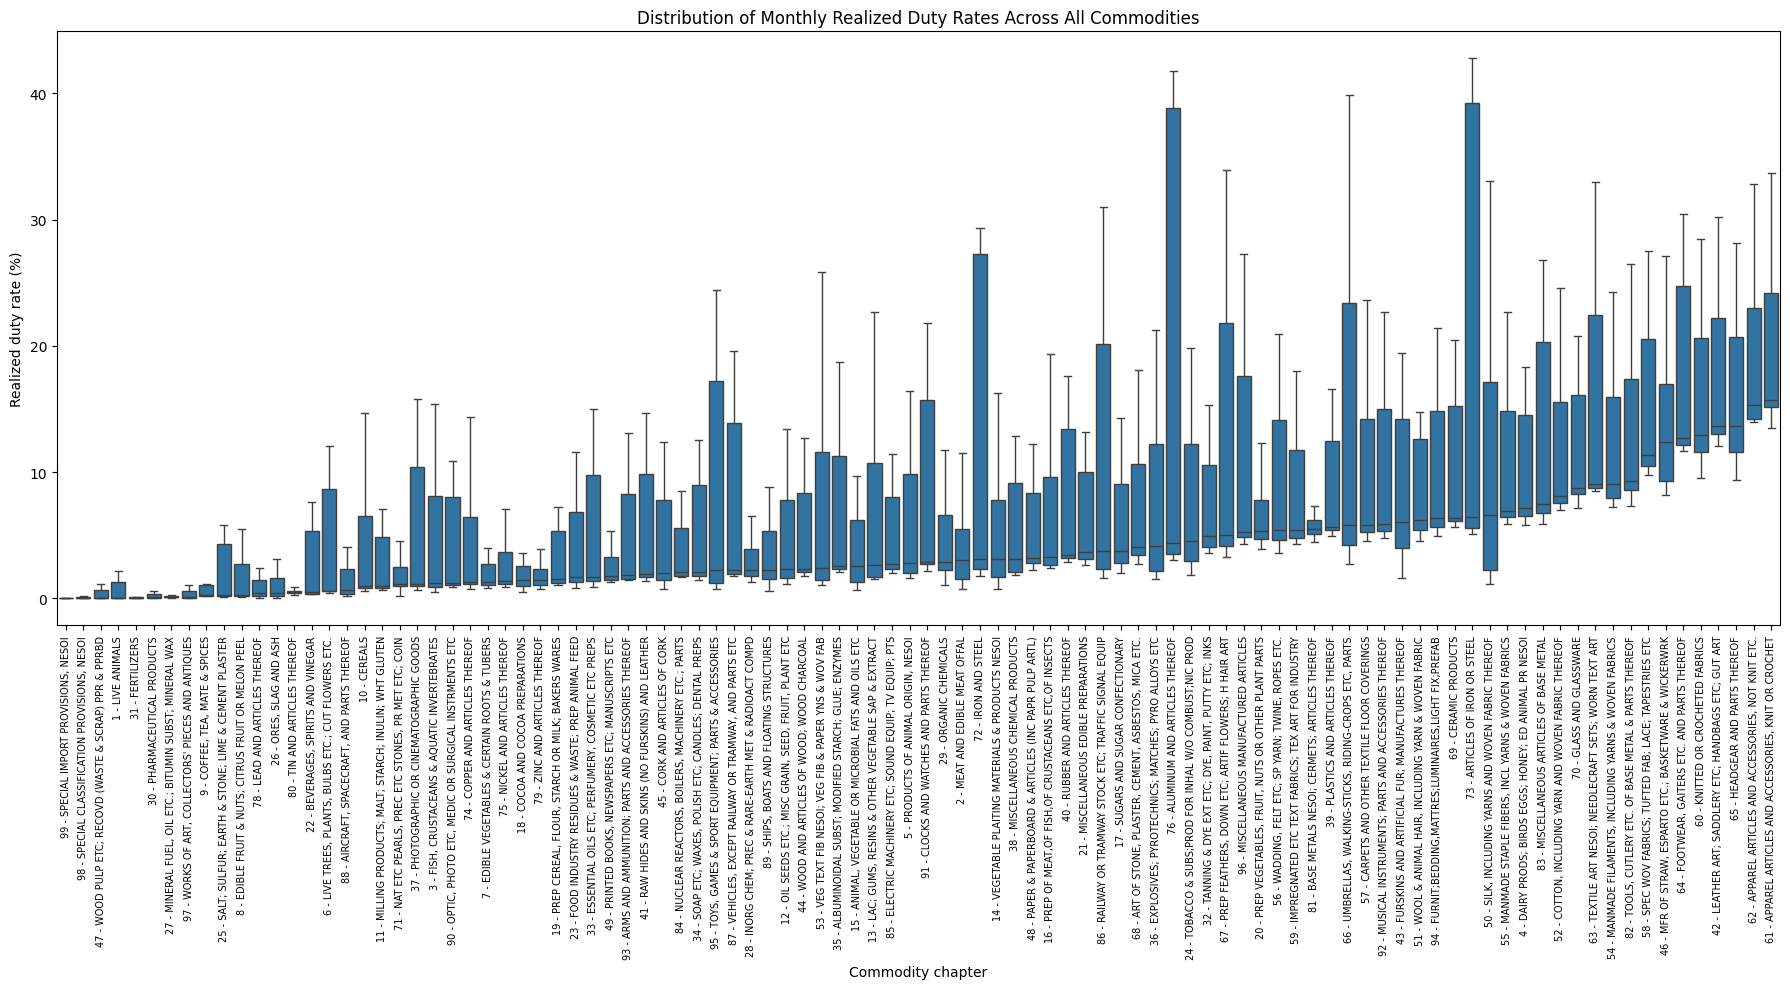

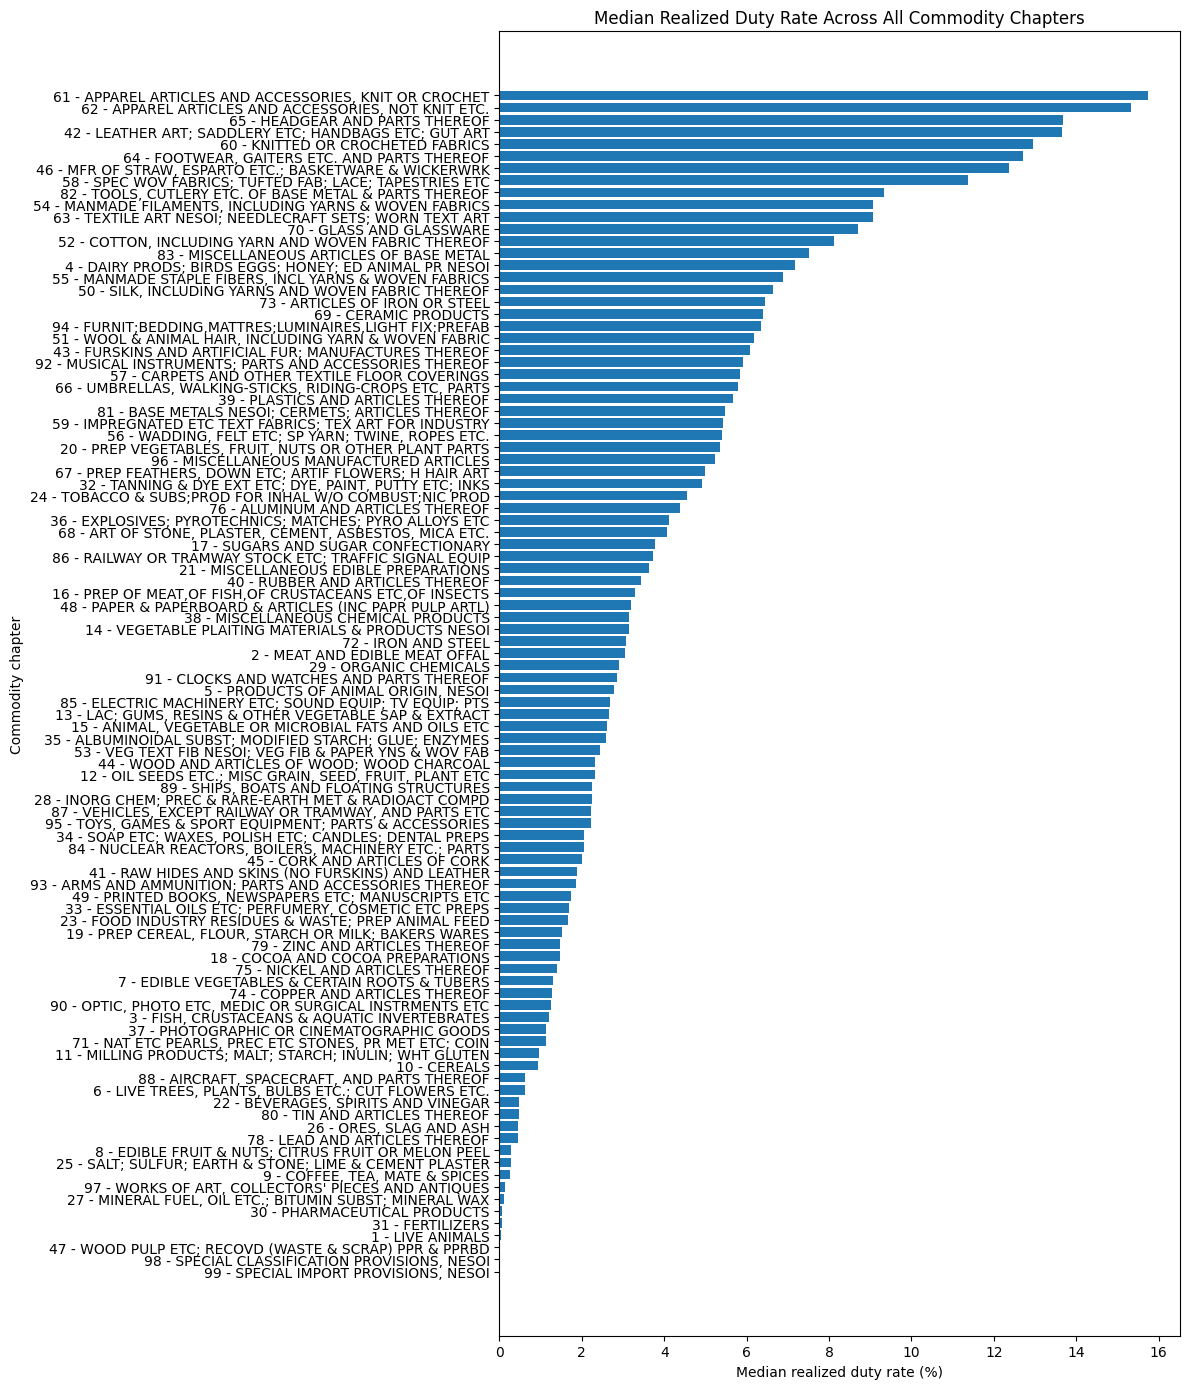

10 LOWEST MEDIAN DUTY RATES


,I_COMMODITY,I_COMMODITY_SDESC,median_rate,mean_rate,std_rate,months,category
97,99,"SPECIAL IMPORT PROVISIONS, NESOI",0.000,0.000,0.000,38,"99 - SPECIAL IMPORT PROVISIONS, NESOI"
96,98,"SPECIAL CLASSIFICATION PROVISIONS, NESOI",0.010,0.051,0.050,38,"98 - SPECIAL CLASSIFICATION PROVISIONS, NESOI"
46,47,WOOD PULP ETC; RECOVD (WASTE & SCRAP) PPR & PPRBD,0.022,0.702,1.417,38,47 - WOOD PULP ETC; RECOVD (WASTE & SCRAP) PPR...
0,1,LIVE ANIMALS,0.050,0.656,0.737,38,1 - LIVE ANIMALS
30,31,FERTILIZERS,0.065,0.279,0.514,38,31 - FERTILIZERS
29,30,PHARMACEUTICAL PRODUCTS,0.070,0.172,0.202,38,30 - PHARMACEUTICAL PRODUCTS
26,27,"MINERAL FUEL, OIL ETC.; BITUMIN SUBST; MINERAL...",0.104,0.111,0.079,38,"27 - MINERAL FUEL, OIL ETC.; BITUMIN SUBST; MI..."
95,97,"WORKS OF ART, COLLECTORS' PIECES AND ANTIQUES",0.139,0.328,0.358,38,"97 - WORKS OF ART, COLLECTORS' PIECES AND ANTI..."
8,9,"COFFEE, TEA, MATE & SPICES",0.253,2.535,4.987,38,"9 - COFFEE, TEA, MATE & SPICES"
24,25,SALT; SULFUR; EARTH & STONE; LIME & CEMENT PLA...,0.284,2.072,2.204,38,25 - SALT; SULFUR; EARTH & STONE; LIME & CEMEN...


10 HIGHEST MEDIAN DUTY RATES


,I_COMMODITY,I_COMMODITY_SDESC,median_rate,mean_rate,std_rate,months,category
60,61,"APPAREL ARTICLES AND ACCESSORIES, KNIT OR CROCHET",15.730,20.069,6.500,38,"61 - APPAREL ARTICLES AND ACCESSORIES, KNIT OR..."
61,62,"APPAREL ARTICLES AND ACCESSORIES, NOT KNIT ETC.",15.316,19.403,6.236,38,"62 - APPAREL ARTICLES AND ACCESSORIES, NOT KNI..."
64,65,HEADGEAR AND PARTS THEREOF,13.666,15.905,5.490,38,65 - HEADGEAR AND PARTS THEREOF
41,42,LEATHER ART; SADDLERY ETC; HANDBAGS ETC; GUT ART,13.660,18.028,6.156,38,42 - LEATHER ART; SADDLERY ETC; HANDBAGS ETC; ...
59,60,KNITTED OR CROCHETED FABRICS,12.946,16.504,6.103,38,60 - KNITTED OR CROCHETED FABRICS
63,64,"FOOTWEAR, GAITERS ETC. AND PARTS THEREOF",12.709,18.068,6.969,38,"64 - FOOTWEAR, GAITERS ETC. AND PARTS THEREOF"
45,46,"MFR OF STRAW, ESPARTO ETC.; BASKETWARE & WICKE...",12.358,14.915,6.830,38,"46 - MFR OF STRAW, ESPARTO ETC.; BASKETWARE & ..."
57,58,SPEC WOV FABRICS; TUFTED FAB; LACE; TAPESTRIES...,11.368,15.673,6.230,38,58 - SPEC WOV FABRICS; TUFTED FAB; LACE; TAPES...
80,82,"TOOLS, CUTLERY ETC. OF BASE METAL & PARTS THEREOF",9.324,13.800,6.365,38,"82 - TOOLS, CUTLERY ETC. OF BASE METAL & PARTS..."
53,54,"MANMADE FILAMENTS, INCLUDING YARNS & WOVEN FAB...",9.075,12.564,5.726,38,"54 - MANMADE FILAMENTS, INCLUDING YARNS & WOVE..."


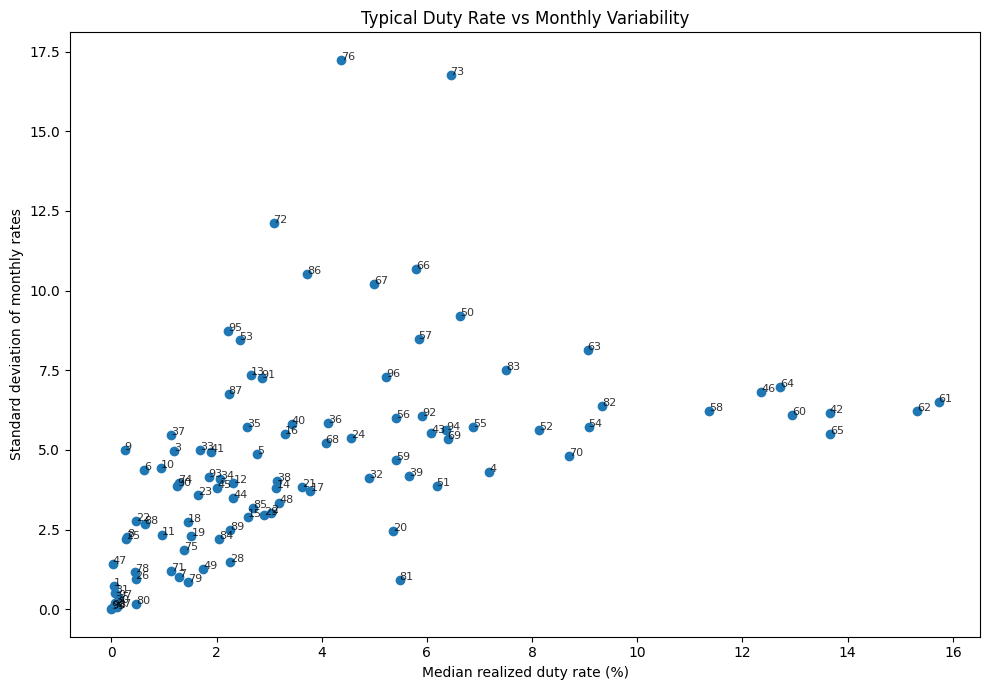

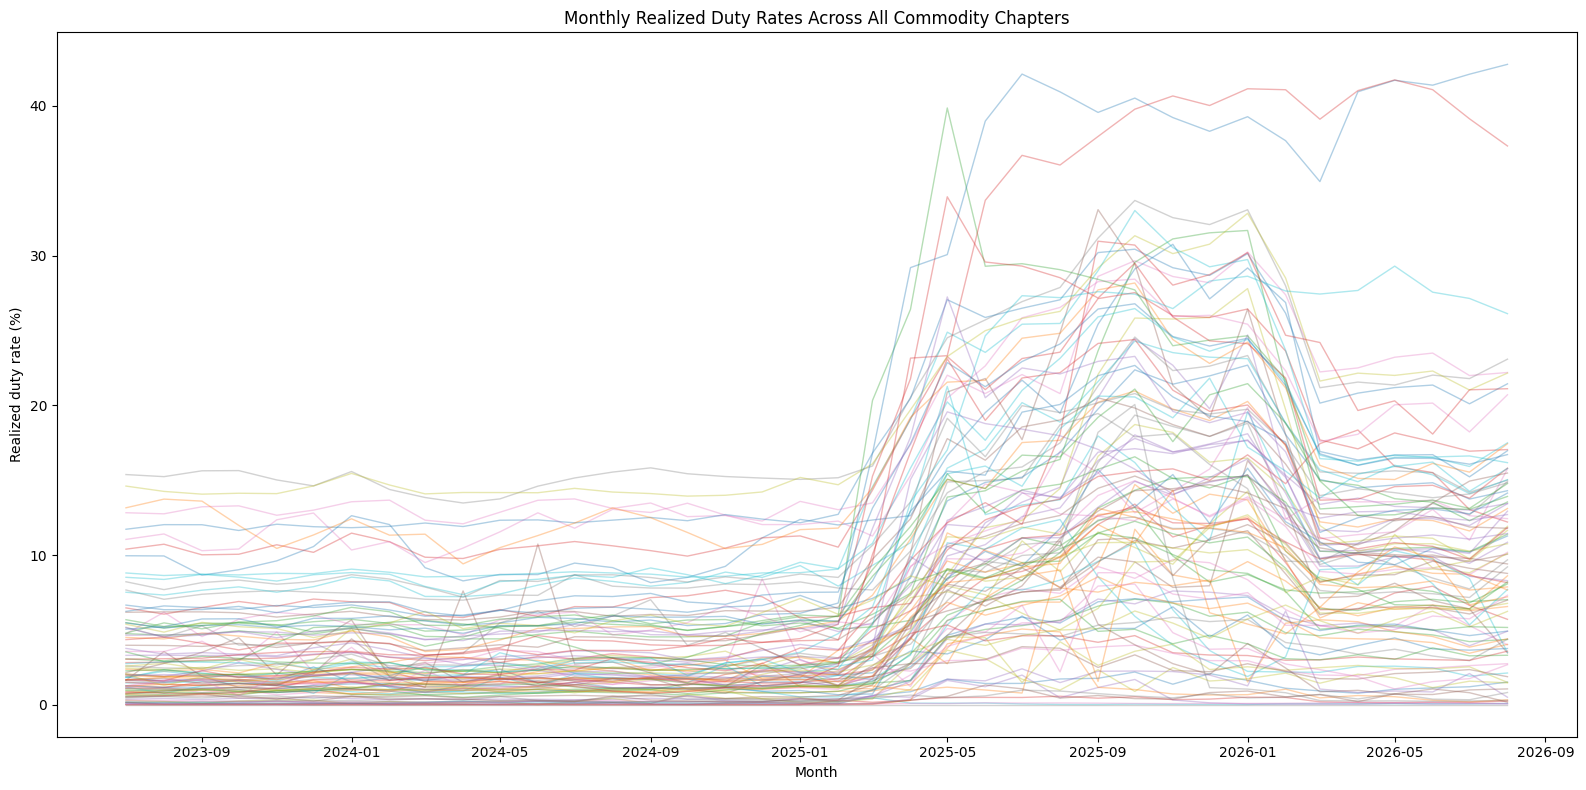

In [ ]:
df_viz["category"] = (
    df_viz["I_COMMODITY"].astype(int).astype(str)
    + " - "
    + df_viz["I_COMMODITY_SDESC"]
)

category_order = (
    df_viz.groupby("category")["duty_rate"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(18, 10))

sns.boxplot(
    data=df_viz,
    x="category",
    y="duty_rate",
    order=category_order,
    showfliers=False
)

plt.title("Distribution of Monthly Realized Duty Rates Across All Commodities")
plt.xlabel("Commodity chapter")
plt.ylabel("Realized duty rate (%)")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

ranking = (
    df_viz.groupby(["I_COMMODITY", "I_COMMODITY_SDESC"])
    .agg(
        median_rate=("duty_rate", "median"),
        mean_rate=("duty_rate", "mean"),
        std_rate=("duty_rate", "std"),
        months=("time", "nunique")
    )
    .reset_index()
    .sort_values("median_rate", ascending=True)
)

ranking["category"] = (
    ranking["I_COMMODITY"].astype(int).astype(str)
    + " - "
    + ranking["I_COMMODITY_SDESC"]
)

plt.figure(figsize=(12, 14))

plt.barh(
    ranking["category"],
    ranking["median_rate"]
)

plt.xlabel("Median realized duty rate (%)")
plt.ylabel("Commodity chapter")
plt.title("Median Realized Duty Rate Across All Commodity Chapters")
plt.tight_layout()
plt.show()

print("10 LOWEST MEDIAN DUTY RATES")
display(ranking.head(10).round(3))

print("10 HIGHEST MEDIAN DUTY RATES")
display(ranking.tail(10).sort_values(
    "median_rate", ascending=False
).round(3))

plt.figure(figsize=(10, 7))

plt.scatter(
    ranking["median_rate"],
    ranking["std_rate"]
)

for _, row in ranking.iterrows():
    plt.annotate(
        str(int(row["I_COMMODITY"])),
        (row["median_rate"], row["std_rate"]),
        fontsize=8,
        alpha=0.8
    )

plt.xlabel("Median realized duty rate (%)")
plt.ylabel("Standard deviation of monthly rates")
plt.title("Typical Duty Rate vs Monthly Variability")
plt.tight_layout()
plt.show()


monthly_all = df_viz.pivot_table(
    index="time",
    columns="category",
    values="duty_rate",
    aggfunc="mean"
).sort_index()

plt.figure(figsize=(16, 8))

for category in monthly_all.columns:
    plt.plot(
        monthly_all.index,
        monthly_all[category],
        alpha=0.35,
        linewidth=1
    )

plt.title("Monthly Realized Duty Rates Across All Commodity Chapters")
plt.xlabel("Month")
plt.ylabel("Realized duty rate (%)")
plt.tight_layout()
plt.show()

#Data Cleaning

## Define Fixed Parameters

In [ ]:
SEED = 607

WINDOWS = {
    "pre": ("2024-03-01", "2024-12-01"),
    "post": ("2025-03-01", "2025-12-01")
}

MIN_PRE_IMPORTS = 1e7

B_MEAN = 10_000
B_AGG = 5_000
COV_REPS = 500

## Prepare Data

In [ ]:
clean = df.copy()

clean = clean.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

clean = clean.rename(columns={
    "I_COMMODITY": "chapter",
    "I_COMMODITY_SDESC": "desc",
    "GEN_VAL_MO": "gen_val",
    "CON_VAL_MO": "con_val",
    "DUT_VAL_MO": "dut_val",
    "CAL_DUT_MO": "cal_dut",
    "time": "month"
})

clean["month"] = pd.to_datetime(clean["month"])

clean["chapter"] = pd.to_numeric(
    clean["chapter"], errors="coerce"
)

num_cols = [
    "gen_val", "con_val", "dut_val", "cal_dut"
]

clean[num_cols] = clean[num_cols].apply(
    pd.to_numeric, errors="coerce"
)

clean = clean.dropna(
    subset=["chapter", "month"]
).copy()

clean["chapter"] = clean["chapter"].astype(int)

clean = clean[
    ~clean["chapter"].isin([98, 99])
].copy()

print("Shape:", clean.shape)
print("Months:", clean["month"].min(),
      "to", clean["month"].max())
print("Number of chapters:", clean["chapter"].nunique())
print("Duplicate chapter-months:",
      clean.duplicated(["chapter", "month"]).sum())
print("Missing values:\n", clean[num_cols].isna().sum())

Shape: (3648, 7)
Months: 2023-07-01 00:00:00 to 2026-08-01 00:00:00
Number of chapters: 96
Duplicate chapter-months: 0
Missing values:
 gen_val    0
con_val    0
dut_val    0
cal_dut    0
dtype: int64


# Feature Engineering

## Calculate Effective Tariff Rate

In [ ]:
clean["etr_con"] = np.where(clean["con_val"] > 0, clean["cal_dut"] / clean["con_val"], np.nan)
clean["etr_dut"] = np.where(clean["dut_val"] > 0, clean["cal_dut"] / clean["dut_val"], np.nan)
print(clean[["etr_con", "etr_dut"]].describe().round(4))
print("Rows with etr_con > 1:", (clean["etr_con"] > 1).sum())

         etr_con    etr_dut
count  3648.0000  3647.0000
mean      0.0735     0.1394
std       0.0759     0.0815
min       0.0000     0.0013
25%       0.0166     0.0834
50%       0.0491     0.1243
75%       0.1095     0.1856
max       0.4278     0.5016
Rows with etr_con > 1: 0


## Calculate Aggregate Effective Tariff Rate

In [ ]:
agg = clean.groupby("month")[
    ["con_val", "dut_val", "cal_dut"]
].sum()

agg["etr_con"] = agg["cal_dut"] / agg["con_val"]
agg["etr_dut"] = agg["cal_dut"] / agg["dut_val"]

print(agg[["etr_con", "etr_dut"]].round(4))

            etr_con  etr_dut
month                       
2023-07-01   0.0256   0.0778
2023-08-01   0.0248   0.0757
2023-09-01   0.0245   0.0765
2023-10-01   0.0236   0.0754
2023-11-01   0.0226   0.0712
2023-12-01   0.0243   0.0735
2024-01-01   0.0257   0.0793
2024-02-01   0.0253   0.0789
2024-03-01   0.0230   0.0748
2024-04-01   0.0226   0.0714
2024-05-01   0.0233   0.0727
2024-06-01   0.0244   0.0765
2024-07-01   0.0259   0.0791
2024-08-01   0.0261   0.0813
2024-09-01   0.0251   0.0820
2024-10-01   0.0245   0.0813
2024-11-01   0.0245   0.0787
2024-12-01   0.0243   0.0796
2025-01-01   0.0230   0.0829
2025-02-01   0.0242   0.0850
2025-03-01   0.0386   0.1389
2025-04-01   0.0751   0.1901
2025-05-01   0.0949   0.2050
2025-06-01   0.0973   0.1934
2025-07-01   0.0994   0.2113
2025-08-01   0.1101   0.2332
2025-09-01   0.1104   0.2544
2025-10-01   0.1139   0.2614
2025-11-01   0.1032   0.2467
2025-12-01   0.0982   0.2355
2026-01-01   0.1039   0.2452
2026-02-01   0.0891   0.2161
2026-03-01   0

# Function Definition

## window_rates(data, start, end)
split data into pre and post period

In [ ]:
def window_rates(data, start, end):
    w = data[
        (data["month"] >= start) &
        (data["month"] <= end)
    ]

    g = w.groupby(
        ["chapter", "desc"], as_index=False
    )[["con_val", "dut_val", "cal_dut"]].sum()

    g["etr_con"] = np.where(
        g["con_val"] > 0,
        g["cal_dut"] / g["con_val"],
        np.nan
    )

    g["etr_dut"] = np.where(
        g["dut_val"] > 0,
        g["cal_dut"] / g["dut_val"],
        np.nan
    )

    return g

## build_panel(data, windows, min_pre,rate)
Compare pre and post period

In [ ]:
def build_panel(data, windows, min_pre=MIN_PRE_IMPORTS,
                rate="d_etr"):

    pre = window_rates(data, *windows["pre"]).add_suffix("_pre")

    post = window_rates(data, *windows["post"]).add_suffix("_post")

    p = pre.merge(
        post,
        left_on="chapter_pre",
        right_on="chapter_post",
        how="inner"
    )

    p = p.rename(columns={
            "chapter_pre": "chapter",
            "desc_pre": "desc"
        }
    ).drop(columns=["chapter_post", "desc_post"])

    p["d_etr"] = p["etr_con_post"] - p["etr_con_pre"]
    p["d_etr_dut"] = p["etr_dut_post"] - p["etr_dut_pre"]
    p["duty_change"] = p["cal_dut_post"] - p["cal_dut_pre"]
    p["log_imp_ratio"] = np.log(p["con_val_post"] / p["con_val_pre"])
    p = p[
        (p["con_val_pre"] >= min_pre) &
        p[rate].notna()
    ].copy()

    p["weight"] = p["con_val_pre"] / p["con_val_pre"].sum()

    if rate != "d_etr":
        p["d_etr"] = p[rate]

    return p.reset_index(drop=True)

# Data Description

## Split data to pre & post

In [ ]:
panel = build_panel(clean, WINDOWS)

#harmonise all metals together
panel["metals"] = panel["chapter"].between(
    72, 83
).astype(int)

print(panel[
    ["chapter", "desc", "etr_con_pre",
     "etr_con_post", "d_etr"]
].head())

print("Mean chapter change:",
      panel["d_etr"].mean().round(4))

print("Share of chapters increasing:",
      (panel["d_etr"] > 0).mean().round(3))

   chapter                                               desc  etr_con_pre  \
0        1                                       LIVE ANIMALS     0.000237   
1        2                         MEAT AND EDIBLE MEAT OFFAL     0.022912   
2        3          FISH, CRUSTACEANS & AQUATIC INVERTEBRATES     0.008166   
3        4  DAIRY PRODS; BIRDS EGGS; HONEY; ED ANIMAL PR N...     0.066921   
4        5                   PRODUCTS OF ANIMAL ORIGIN, NESOI     0.020776   

   etr_con_post     d_etr  
0      0.014469  0.014232  
1      0.080331  0.057418  
2      0.089129  0.080964  
3      0.121427  0.054507  
4      0.108108  0.087332  
Mean chapter change: 0.0837
Share of chapters increasing: 0.99


## Correlation between import size and import-level etc

In [ ]:
panel["imports_pre"] = panel["con_val_pre"]
print(panel[["imports_pre", "d_etr"]].corr())

             imports_pre     d_etr
imports_pre     1.000000 -0.077685
d_etr          -0.077685  1.000000


The correlation between pre-period import size and the change in effective rate is about -0.08. That is very weak: how large a chapter is tells us almost nothing about how much its rate rose.

## Kendall's Tau

In [ ]:
def tau_boot(x, y, B=2_000, alpha=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(x)
    tau_hat = stats.kendalltau(x, y).statistic
    boots = np.empty(B)
    for b in range(B):
        i = rng.integers(0, n, n)
        boots[b] = stats.kendalltau(x[i], y[i]).statistic
    return tau_hat, np.nanquantile(boots, [alpha / 2, 1 - alpha / 2])

pairs = [("Pre-period imports vs change", panel["con_val_pre"].to_numpy(float)),
         ("Pre-period effective rate vs change", panel["etr_con_pre"].to_numpy(float))]
y = panel["d_etr"].to_numpy(float)

rows = []
for name, x in pairs:
    res = stats.kendalltau(x, y)
    tau_hat, (lo, hi) = tau_boot(x, y)
    rows.append({"pair": name, "kendall_tau": tau_hat, "ci_low": lo, "ci_high": hi,
                 "p_value": res.pvalue, "pearson_r": np.corrcoef(x, y)[0, 1]})
tab_tau = pd.DataFrame(rows).set_index("pair")
print(tab_tau.round(4))

                                     kendall_tau  ci_low  ci_high  p_value  \
pair                                                                         
Pre-period imports vs change             -0.0811 -0.2306   0.0663   0.2415   
Pre-period effective rate vs change       0.4781  0.3708   0.5746   0.0000   

                                     pearson_r  
pair                                            
Pre-period imports vs change           -0.0777  
Pre-period effective rate vs change     0.4453  


##Graph for Correlation and Kendal

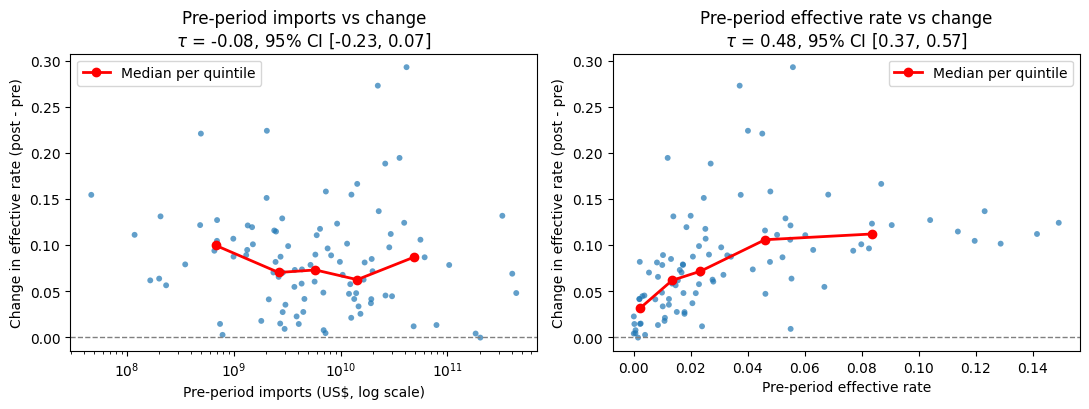

In [ ]:
y = panel["d_etr"].to_numpy(float)
panels = [
    ("Pre-period imports (US$, log scale)", panel["con_val_pre"].to_numpy(float),
     "Pre-period imports vs change", True),
    ("Pre-period effective rate", panel["etr_con_pre"].to_numpy(float),
     "Pre-period effective rate vs change", False),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (xlabel, x, key, logx) in zip(axes, panels):
    ax.scatter(x, y, s=18, alpha=0.7, edgecolor="none")

    # Median change within 5 equal-sized bins of x (a rank-friendly trend line)
    bins = pd.qcut(pd.Series(x), q=5, duplicates="drop")
    trend = pd.DataFrame({"x": x, "y": y, "bin": bins}).groupby("bin", observed=True).median()
    ax.plot(trend["x"], trend["y"], color="red", marker="o", lw=2, label="Median per quintile")

    ax.axhline(0, color="grey", ls="--", lw=1)
    if logx:
        ax.set_xscale("log")
    t = tab_tau.loc[key]
    ax.set_title(f"{key}\n$\\tau$ = {t['kendall_tau']:.2f}, 95% CI [{t['ci_low']:.2f}, {t['ci_high']:.2f}]")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Change in effective rate (post - pre)")
    ax.legend(loc="upper right" if not logx else "best")

plt.tight_layout()
plt.show()

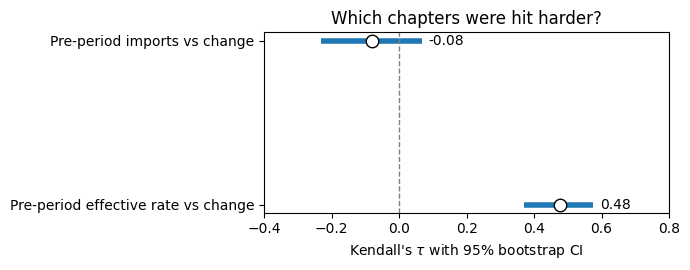

In [ ]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ypos = np.arange(len(tab_tau))[::-1]
for yy, (name, r) in zip(ypos, tab_tau.iterrows()):
    ax.hlines(yy, r["ci_low"], r["ci_high"], lw=4)
    ax.plot(r["kendall_tau"], yy, "o", color="white", markeredgecolor="black", ms=9, zorder=3)
    ax.text(r["ci_high"] + 0.02, yy, f"{r['kendall_tau']:.2f}", va="center")

ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(ypos)
ax.set_yticklabels(tab_tau.index)
ax.set_xlim(-0.4, 0.8)
ax.set_xlabel("Kendall's $\\tau$ with 95% bootstrap CI")
ax.set_title("Which chapters were hit harder?")
plt.tight_layout()
plt.show()

# Data Visualisation for Pre & Post

## Aggregate effective rate over time

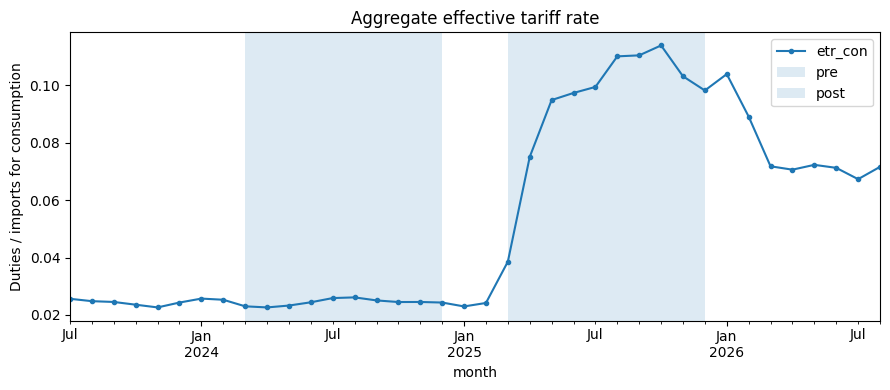

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
agg["etr_con"].plot(ax=ax, marker="o", ms=3)
for k, (s, e) in WINDOWS.items():
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), alpha=0.15, label=k)
ax.set_ylabel("Duties / imports for consumption")
ax.set_title("Aggregate effective tariff rate")
ax.legend()
plt.tight_layout()
plt.show()

## ECDF of chapter-level changes

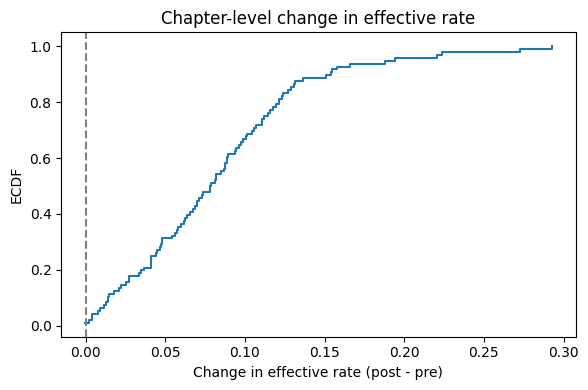

In [ ]:
x = np.sort(panel["d_etr"].values)
y = np.arange(1, len(x) + 1) / len(x)
fig, ax = plt.subplots(figsize=(6, 4))
ax.step(x, y, where="post")
ax.axvline(0, color="grey", ls="--")
ax.set_xlabel("Change in effective rate (post - pre)")
ax.set_ylabel("ECDF")
ax.set_title("Chapter-level change in effective rate")
plt.tight_layout()
plt.show()

## Concentration Analysis

In [ ]:
# do a few chapters carry the duty increase?
conc = panel.sort_values("duty_change", ascending=False)
tot = panel["duty_change"].sum()
print("Share of total net duty increase from top 5 / 10 chapters (can exceed 1 if other chapters fall):",
      round(conc["duty_change"].head(5).sum() / tot, 3), "/", round(conc["duty_change"].head(10).sum() / tot, 3))
print("Share of pre-period imports in those top 10:", round(conc["weight"].head(10).sum(), 3))
print(conc.head(10)[["chapter", "desc", "duty_change", "d_etr"]].round(4).to_string(index=False))

Share of total net duty increase from top 5 / 10 chapters (can exceed 1 if other chapters fall): 0.608 / 0.746
Share of pre-period imports in those top 10: 0.578
 chapter                                               desc  duty_change  d_etr
      87 VEHICLES, EXCEPT RAILWAY OR TRAMWAY, AND PARTS ETC  35272127906 0.1316
      85 ELECTRIC MACHINERY ETC; SOUND EQUIP; TV EQUIP; PTS  28797363100 0.0688
      84   NUCLEAR REACTORS, BOILERS, MACHINERY ETC.; PARTS  28602722964 0.0478
      73                          ARTICLES OF IRON OR STEEL   9203042030 0.2929
      90 OPTIC, PHOTO ETC, MEDIC OR SURGICAL INSTRMENTS ETC   8116795854 0.0782
      95 TOYS, GAMES & SPORT EQUIPMENT; PARTS & ACCESSORIES   5539368922 0.1944
      76                      ALUMINUM AND ARTICLES THEREOF   5312932744 0.2728
      94 FURNIT;BEDDING,MATTRES;LUMINAIRES,LIGHT FIX;PREFAB   4946277403 0.1057
      39                      PLASTICS AND ARTICLES THEREOF   4656424191 0.0866
      61  APPAREL ARTICLES AND ACCESSO

- The top 5 chapters account for about 61% of the net increase in duties collected, and the top 10 for about 75%.
- Those same 10 chapters hold only about 58% of pre-period imports, so the duty increase is somewhat more concentrated than trade itself.
- The three biggest contributors in dollars are vehicles (ch. 87), electrical machinery (ch. 85) and machinery (ch. 84). They matter because of their size, even though their rate changes (4.8 to 13.2 points) are only moderate.
- Chapters with the largest *rate* increases (iron and steel, aluminium, toys) rank lower in dollars. This is why the unweighted and weighted answers differ.

## Understanding Import Growth

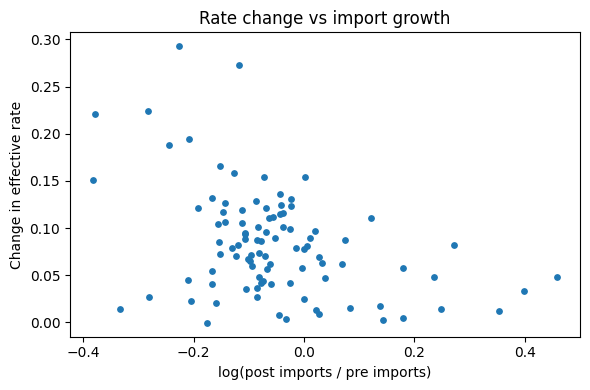

In [ ]:
# did import values jump where rates rose?
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(panel["log_imp_ratio"], panel["d_etr"], s=15)
ax.set_xlabel("log(post imports / pre imports)")
ax.set_ylabel("Change in effective rate")
ax.set_title("Rate change vs import growth")
plt.tight_layout()
plt.show()

# Statistical Analysis

## Function definitions

In [ ]:
def make_agg_stat(cal_pre, con_pre, cal_post, con_post):
    def f(idx):
        return cal_post[idx].sum(-1) / con_post[idx].sum(-1) - cal_pre[idx].sum(-1) / con_pre[idx].sum(-1)
    return f

def jackknife_stats(f_idx, n):
    base = np.arange(n)
    loo = np.array([np.delete(base, i) for i in range(n)])
    return f_idx(loo)

#Standard Wald interval using Jackknife standard error
def ci_wald_jackknife(theta, jack, alpha=0.05):
    n = len(jack)
    se = np.sqrt((n - 1) / n * np.sum((jack - jack.mean()) ** 2))
    z = stats.norm.ppf(1 - alpha / 2)
    return theta - z * se, theta + z * se, se

def ci_t_mean(x, alpha=0.05):
    n = len(x); se = x.std(ddof=1) / np.sqrt(n); t = stats.t.ppf(1 - alpha / 2, n - 1)
    return x.mean() - t * se, x.mean() + t * se, se

def ci_percentile(boot, alpha=0.05):
    return tuple(np.quantile(boot, [alpha / 2, 1 - alpha / 2]))

def ci_basic(theta, boot, alpha=0.05):
    q_lo, q_hi = np.quantile(boot, [alpha / 2, 1 - alpha / 2])
    return 2 * theta - q_hi, 2 * theta - q_lo

def ci_boot_t(theta, se_hat, boot, se_boot, alpha=0.05):
    t_star = (boot - theta) / se_boot
    q_lo, q_hi = np.quantile(t_star, [alpha / 2, 1 - alpha / 2])
    return theta - q_hi * se_hat, theta - q_lo * se_hat

# all intervals for the unweighted mean of chapter changes
def intervals_mean(x, B=10_000, alpha=0.05, rng=np.random.default_rng(SEED)):
    n = len(x)
    theta = x.mean()
    idx = rng.integers(0, n, size=(B, n))
    xb = x[idx]
    boot = xb.mean(1)
    se_b = xb.std(1, ddof=1) / np.sqrt(n)
    jack = (x.sum() - x) / (n - 1)
    out = {}
    lo, hi, _ = ci_t_mean(x, alpha)
    out["CLT (t)"] = (lo, hi)
    out["Percentile"] = ci_percentile(boot, alpha)
    out["Basic"] = ci_basic(theta, boot, alpha)
    out["Bootstrap-t"] = ci_boot_t(theta, x.std(ddof=1) / np.sqrt(n), boot, se_b, alpha)
    return theta, out, boot

# all intervals for the aggregate-rate change
# bootstrap-t uses a nested bootstrap for each SE
def intervals_agg(f, n, B=5_000, B_inner=200, alpha=0.05, rng=np.random.default_rng(SEED)):
    theta = float(f(np.arange(n)))
    idx = rng.integers(0, n, size=(B, n))
    boot = f(idx)
    jack = jackknife_stats(f, n)
    out = {}
    lo, hi, se_jk = ci_wald_jackknife(theta, jack, alpha)
    out["Wald (jackknife SE)"] = (lo, hi)
    out["Percentile"] = ci_percentile(boot, alpha)
    out["Basic"] = ci_basic(theta, boot, alpha)
    Bo = min(B, 1_500)
    se_in = np.empty(Bo)
    for b in range(Bo):
        inner = idx[b][rng.integers(0, n, size=(B_inner, n))]
        se_in[b] = f(inner).std(ddof=1)
    out["Bootstrap-t"] = ci_boot_t(theta, se_jk, boot[:Bo], se_in, alpha)
    return theta, out, dict(boot=boot, se_jk=se_jk)

def as_table(ci_dict):
    t = pd.DataFrame(ci_dict, index=["lower", "upper"]).T
    t["width"] = t["upper"] - t["lower"]
    return t

## Analysis of Unweighted Change

In [ ]:
d = panel["d_etr"].to_numpy(float)
n = len(d)
thetaA, ciA, infoA = intervals_mean(d, B=B_MEAN)
tabA = as_table(ciA)
print(f"Chapters: {n}")
print(f"Unweighted mean change = {thetaA:.4f}")
print(tabA.round(4))
print(f"Skewness of chapter changes:", round(stats.skew(d), 2))
print(f"Excess kurtosis:", round(stats.kurtosis(d), 2))

Chapters: 96
Unweighted mean change = 0.0837
              lower   upper   width
CLT (t)      0.0721  0.0952  0.0231
Percentile   0.0728  0.0953  0.0225
Basic        0.0720  0.0945  0.0225
Bootstrap-t  0.0730  0.0964  0.0235
Skewness of chapter changes: 1.12
Excess kurtosis: 1.93


In [ ]:
# Chapters with decreases
print("Chapters with decreases:")
print(panel.loc[d < 0, ["desc", "d_etr"]])

Chapters with decreases:
                                                 desc     d_etr
26  MINERAL FUEL, OIL ETC.; BITUMIN SUBST; MINERAL... -0.000538




**Main result**
- 96 chapters. The average chapter's effective tariff rate rose by 8.4%
- Every chapter counts equally, whatever its import value.
- Only 1 of 96 chapters fell: *Mineral fuel, oil etc.*, by about 0.05 points, which is effectively zero. So 95 of 96 (99%) rose.

**Confidence intervals (95%)**

| Method | Interval | Width |
|---|---|---|
| CLT (t) | [0.0721, 0.0952] | 0.0231 |
| Percentile | [0.0728, 0.0953] | 0.0225 |
| Basic | [0.0720, 0.0945] | 0.0225 |
| Bootstrap-t | [0.0730, 0.0964] | 0.0235 |

- All four intervals are almost identical and sit well above zero, so the average increase is clearly positive.
- The bootstrap intervals agree with the t-interval, so the result does not hinge on a normality assumption.

**Shape of the distribution**
- Skewness = 1.12: moderately right-skewed. A few chapters rose much more than the rest.
- Excess kurtosis = 1.93: heavier tails than a normal distribution.
- The boxplot flags four upper outliers (above 0.216): umbrellas and walking-sticks, prepared feathers and artificial flowers, aluminium, and iron and steel articles. The last two are metal products and rose by about 27 to 29 points.
- Skew and heavy tails are the reason to compare bootstrap intervals with the t-interval, and the median is close to the mean (0.0786 vs 0.0837), so outliers are not driving the result.

**Conclusion.** The average chapter-level effective rate rose by roughly 7 to 10 points. This is a before/after comparison, so it does not show that a particular policy caused the change.

### Histogram of Change

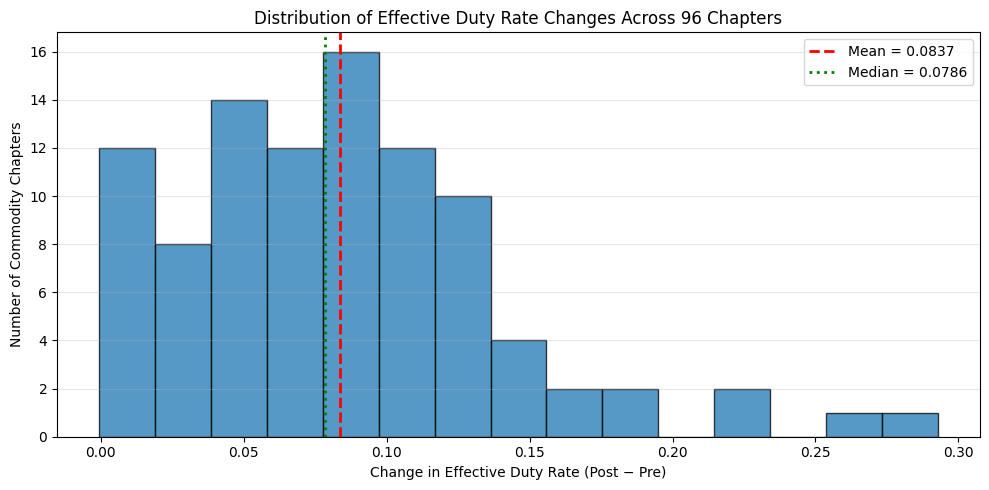

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(d, bins=15, edgecolor="black", alpha=0.75)

plt.axvline(
    thetaA,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {thetaA:.4f}"
)

plt.axvline(
    np.median(d),
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"Median = {np.median(d):.4f}"
)

plt.title("Distribution of Effective Duty Rate Changes Across 96 Chapters")
plt.xlabel("Change in Effective Duty Rate (Post − Pre)")
plt.ylabel("Number of Commodity Chapters")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Boxplot of Change

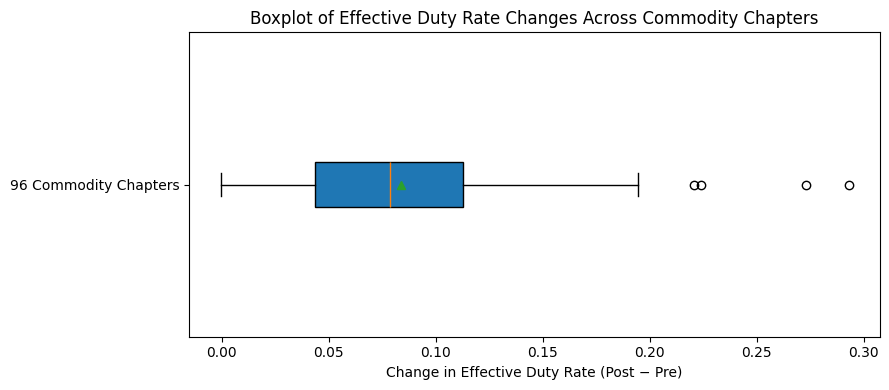

Q1: 0.0436
Q3: 0.1125
IQR: 0.0689
Lower bound: -0.0598
Upper bound: 0.2160
Identified outliers:
                                              desc    d_etr
UMBRELLAS, WALKING-STICKS, RIDING-CROPS ETC, PARTS 0.220784
PREP FEATHERS, DOWN ETC; ARTIF FLOWERS; H HAIR ART 0.223863
                     ALUMINUM AND ARTICLES THEREOF 0.272787
                         ARTICLES OF IRON OR STEEL 0.292850


In [ ]:
plt.figure(figsize=(9, 4))

plt.boxplot(
    d,
    vert=False,
    patch_artist=True,
    showmeans=True
)

plt.title("Boxplot of Effective Duty Rate Changes Across Commodity Chapters")
plt.xlabel("Change in Effective Duty Rate (Post − Pre)")
plt.yticks([1], ["96 Commodity Chapters"])

plt.tight_layout()
plt.show()

#Outliers
Q1 = np.percentile(d, 25)
Q3 = np.percentile(d, 75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (d < lower_bound) | (d > upper_bound)

outliers = panel.loc[outlier_mask].copy()
outliers["d_etr"] = d[outlier_mask]

print(f"Q1: {Q1:.4f}")
print(f"Q3: {Q3:.4f}")
print(f"IQR: {IQR:.4f}")
print(f"Lower bound: {lower_bound:.4f}")
print(f"Upper bound: {upper_bound:.4f}")

print("Identified outliers:")
print(
    outliers[["desc", "d_etr"]]
    .sort_values("d_etr")
    .to_string(index=False)
)

### Bayesian Credible Interval

                                     post_mean  ci_low  ci_high  P(mu > 0)  \
prior                                                                        
Reference (flat; equals t-interval)     0.0837  0.0721   0.0952        1.0   
Weak, centred at 0                      0.0828  0.0713   0.0943        1.0   
Sceptical: worth 20 obs at 0            0.0693  0.0571   0.0814        1.0   

                                     P(mu > 0.05)  
prior                                              
Reference (flat; equals t-interval)        1.0000  
Weak, centred at 0                         1.0000  
Sceptical: worth 20 obs at 0               0.9989  

Frequentist t-interval for comparison: [0.0721 0.0952]


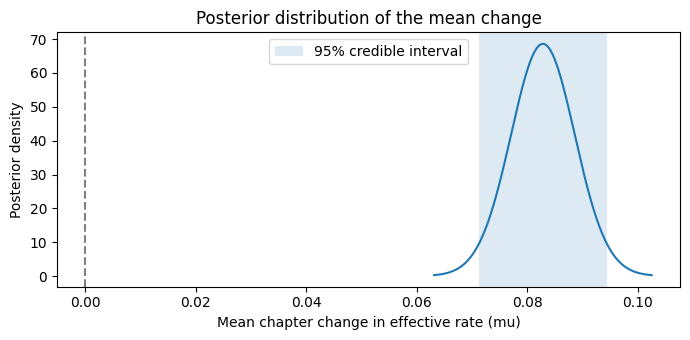

In [ ]:
def nig_posterior(x, mu0, kappa0, a0, b0):
    n, xbar = len(x), x.mean()
    ss = ((x - xbar) ** 2).sum()
    kn = kappa0 + n
    mun = (kappa0 * mu0 + n * xbar) / kn
    an = a0 + n / 2
    bn = b0 + 0.5 * ss + kappa0 * n * (xbar - mu0) ** 2 / (2 * kn)
    scale = np.sqrt(bn / (an * kn))
    return stats.t(df=2 * an, loc=mun, scale=scale)

priors = {
    "Reference (flat; equals t-interval)": dict(mu0=0.0, kappa0=0.0, a0=-0.5, b0=0.0),
    "Weak, centred at 0":                  dict(mu0=0.0, kappa0=1.0, a0=1.0,  b0=0.0025),
    "Sceptical: worth 20 obs at 0":        dict(mu0=0.0, kappa0=20.0, a0=1.0, b0=0.0025),
}
#Define meaningful
THRESH = 0.05

rows = []
for name, pr in priors.items():
    post = nig_posterior(d, **pr)
    lo, hi = post.ppf([0.025, 0.975])
    rows.append({"prior": name, "post_mean": post.mean(), "ci_low": lo, "ci_high": hi,
                 "P(mu > 0)": post.sf(0.0), f"P(mu > {THRESH})": post.sf(THRESH)})
tab_bayes = pd.DataFrame(rows).set_index("prior")
print(tab_bayes.round(4))
print("\nFrequentist t-interval for comparison:", np.round(stats.t.interval(
      0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d)), 4))

# Posterior density plot (weak prior)
post = nig_posterior(d, **priors["Weak, centred at 0"])
grid = np.linspace(post.ppf(0.0005), post.ppf(0.9995), 400)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(grid, post.pdf(grid))
ax.axvline(0, color="grey", ls="--")
ax.axvspan(*post.ppf([0.025, 0.975]), alpha=0.15, label="95% credible interval")
ax.set_xlabel("Mean chapter change in effective rate (mu)")
ax.set_ylabel("Posterior density")
ax.set_title("Posterior distribution of the mean change")
ax.legend()
plt.tight_layout()
plt.show()

## Analysis of Weighted Change

In [ ]:
f_agg = make_agg_stat(panel["cal_dut_pre"].to_numpy(float), panel["con_val_pre"].to_numpy(float),
                      panel["cal_dut_post"].to_numpy(float), panel["con_val_post"].to_numpy(float))

thetaB, ciB, infoB = intervals_agg(f_agg, n, B=B_AGG)
tabB = as_table(ciB)
print(f"Aggregate-rate change = {thetaB:.4f}")
print(tabB.round(4))

Aggregate-rate change = 0.0682
                      lower   upper   width
Wald (jackknife SE)  0.0442  0.0921  0.0479
Percentile           0.0488  0.0947  0.0460
Basic                0.0416  0.0876  0.0460
Bootstrap-t          0.0424  0.0978  0.0554


## Visualisation of Unweighted and Weighted

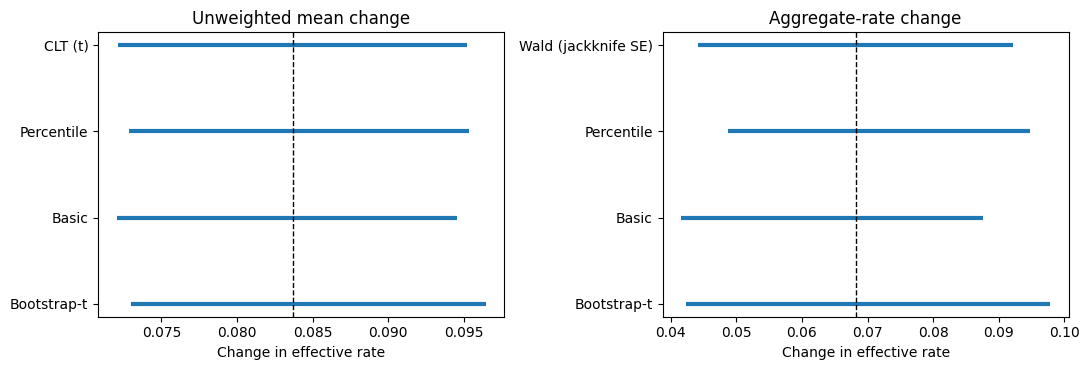

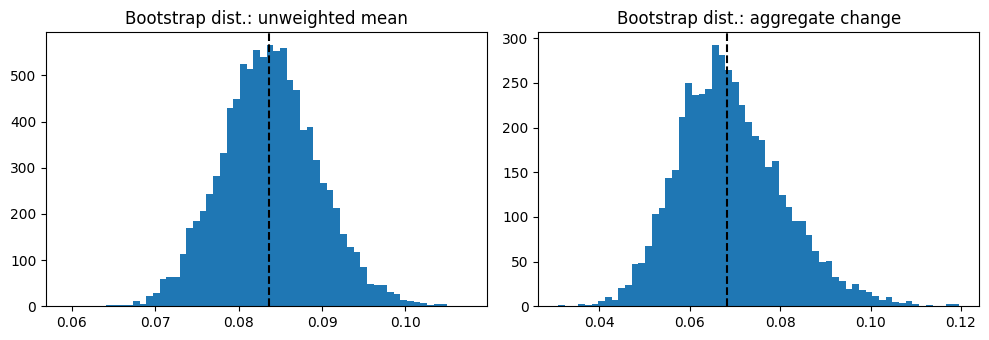

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, tab, th, ttl in [(axes[0], tabA, thetaA, "Unweighted mean change"),
                         (axes[1], tabB, thetaB, "Aggregate-rate change")]:
    ypos = np.arange(len(tab))[::-1]
    for yy, (name, r) in zip(ypos, tab.iterrows()):
        ax.hlines(yy, r["lower"], r["upper"], lw=3)
    ax.axvline(th, color="k", ls="--", lw=1)
    ax.set_yticks(ypos)
    ax.set_yticklabels(tab.index)
    ax.set_title(ttl)
    ax.set_xlabel("Change in effective rate")


plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(infoA, bins=60)
axes[0].axvline(thetaA, color="k", ls="--")
axes[0].set_title("Bootstrap dist.: unweighted mean")

axes[1].hist(infoB["boot"], bins=60)
axes[1].axvline(thetaB, color="k", ls="--")
axes[1].set_title("Bootstrap dist.: aggregate change")
plt.tight_layout()
plt.show()

Main Takeaway

- **Unweighted mean: 0.0837.** The average across chapters, each counted equally.
- **Aggregate-rate change: 0.0682.** Total duties divided by total imports, so large-import chapters count more.
- Both are positive and all eight 95% intervals exclude zero.
- The aggregate figure is **lower** than the unweighted mean. Large chapters such as machinery (ch. 84, +4.8 points) and electrical equipment (ch. 85, +6.9) rose by less than the typical small chapter. Metals, toys and apparel rose more but carry less trade.
- The aggregate intervals are wider (about 0.046 to 0.055 vs 0.023). A few big chapters dominate the total, so the estimate is more sensitive to which chapters are resampled.
- The unweighted mean describes the typical chapter, the aggregate describes the overall duty burden on total imports.

## Additional Tests
Includes:
*   Sign-flip permutation (mean)
*   Sign test (median)
*   Bootstrap t-test (mean)
*   Classical t-test
*   Wilcoxon signed-rank





In [ ]:
def tests_on_changes(d, B=20_000, rng=None):
    rng = rng or np.random.default_rng(SEED)
    n = len(d); obs = d.mean(); res = {}
    signs = rng.choice([-1.0, 1.0], size=(B, n))
    perm = (signs * d).mean(1)
    res["Sign-flip permutation (mean)"] = (np.sum(np.abs(perm) >= abs(obs)) + 1) / (B + 1)
    k, m = int((d > 0).sum()), int((d != 0).sum())
    res["Sign test (median)"] = stats.binomtest(k, m, 0.5).pvalue
    t_obs = obs / (d.std(ddof=1) / np.sqrt(n))
    xb = (d - obs)[rng.integers(0, n, size=(B, n))]
    t_b = xb.mean(1) / (xb.std(1, ddof=1) / np.sqrt(n))
    res["Bootstrap t-test (mean)"] = (np.sum(np.abs(t_b) >= abs(t_obs)) + 1) / (B + 1)
    res["Classical t-test"] = stats.ttest_1samp(d, 0.0).pvalue
    res["Wilcoxon signed-rank"] = stats.wilcoxon(d[d != 0]).pvalue
    return res, dict(share_positive=k / m, mean=obs, median=float(np.median(d)))

pvals, desc = tests_on_changes(d)
tabT = pd.Series(pvals, name="p_value").to_frame()
print(f"Share of chapters with an increase = {desc['share_positive']:.2f} | mean = {desc['mean']:.4f} | median = {desc['median']:.4f}")
pd.set_option("display.float_format", "{:.6e}".format)
print(tabT)

Share of chapters with an increase = 0.99 | mean = 0.0837 | median = 0.0786
                                  p_value
Sign-flip permutation (mean) 4.999750e-05
Sign test (median)           2.448624e-27
Bootstrap t-test (mean)      4.999750e-05
Classical t-test             1.301018e-25
Wilcoxon signed-rank         1.838298e-17



- All five reject "no change" at the 5% level by a wide margin.
- The two resampling p-values (4.99975e-05) are the smallest the procedure can return, 1/(B+1) with B = 20,000. Report them as **p < 0.0001**, not as exact values.
- The tests assume independent chapters. The 96 chapters are the full set of goods and related chapters move together, so treat very small p-values as a sign of a large effect rather than as exact probabilities.
- Agreement between parametric, rank-based and resampling tests shows the finding does not rest on one assumption.

# Independence Testing



## Group Data to Categorical

In [ ]:
df = panel[["chapter", "d_etr"]].copy()
df["chapter"] = df["chapter"].astype(int)

#commodity chapter
labels = ["Agriculture & food",
          "Minerals, chemicals, plastics & rubber",
          "Leather, wood, paper, textiles & footwear",
          "Stone, glass, jewelry & base metals",
          "Machinery, transport, instruments & misc."]
df["group"] = pd.cut(df["chapter"], bins=[0, 24, 40, 67, 83, 97], labels=labels)

#etr
df = df.dropna(subset=["group", "d_etr"])
df["etr_bin"] = pd.qcut(df["d_etr"], q=3, labels=["Low", "Mid", "High"])

### Stacked Bargraph

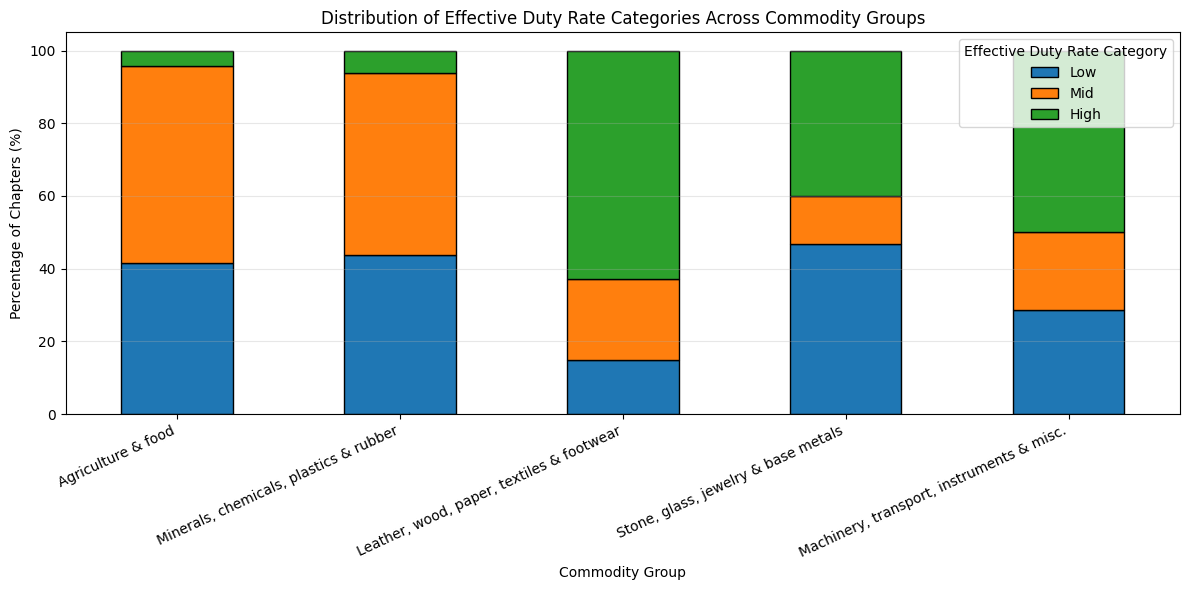

In [ ]:
table = pd.crosstab(df["group"], df["etr_bin"])

table_pct = table.div(table.sum(axis=1), axis=0) * 100

ax = table_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    edgecolor="black"
)

plt.title("Distribution of Effective Duty Rate Categories Across Commodity Groups")
plt.xlabel("Commodity Group")
plt.ylabel("Percentage of Chapters (%)")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Effective Duty Rate Category")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Chi-Square Test for Independence

In [ ]:
table = pd.crosstab(df["group"], df["etr_bin"])

print("Observed counts:")
print(table)

chi2, p_value, dof, expected = chi2_contingency(
    table,
    correction=False
)

#Cramer's V (strength of association)
n = table.to_numpy().sum()
min_dimension = min(table.shape)

cramers_v = np.sqrt(
    chi2 / (n * (min_dimension - 1))
)

print("\nCHI-SQUARE TEST RESULTS")
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4f}")
print(f"Cramer's V: {cramers_v:.3f}")


Observed counts:
etr_bin                                    Low  Mid  High
group                                                    
Agriculture & food                          10   13     1
Minerals, chemicals, plastics & rubber       7    8     1
Leather, wood, paper, textiles & footwear    4    6    17
Stone, glass, jewelry & base metals          7    2     6
Machinery, transport, instruments & misc.    4    3     7

CHI-SQUARE TEST RESULTS
Chi-square statistic: 30.671
Degrees of freedom: 8
P-value: 0.0002
Cramer's V: 0.400


- Null hypothesis: commodity group and change category (low/mid/high tercile) are independent.
- chi-square = 30.67, df = 8, p = 0.0002, Cramér's V = 0.40. We reject independence, with a moderately strong association.
- **Where it comes from:** *Leather, wood, paper, textiles & footwear* has 17 of 27 chapters in the High tercile, while *Agriculture & food* has only 1 of 24 and *Minerals, chemicals, plastics & rubber* only 1 of 16.
- **Caveats:** the terciles split the data into equal thirds by construction, and the group boundaries are fixed chapter ranges, so another cut could change the numbers. The smallest group has 14 chapters, so some expected counts are about 4.7 (below the usual rule of 5). Binning also discards information; a Kruskal-Wallis test on the raw changes across groups is a natural follow-up.

# Conclusion and limitations

**Findings**
1. Effective tariff rates rose across U.S. import chapters between Mar-Dec 2024 and Mar-Dec 2025: +8.4 points on average (unweighted), +6.8 points for the aggregate.
2. The rise was almost universal (95 of 96 chapters) and robust to the choice of interval or test.
3. The size of the rise differs by sector: it was largest in leather, wood, paper, textiles and footwear, and smallest in agriculture and food.

**Limitations**
- Before/after design with no control group: this describes the change, it does not identify its cause.
- Effective rate = duties collected / import value. It reflects tariffs actually paid, and can change when the product or country mix changes.
- HS-2 chapters are broad and can hide large differences between products.
- The post window ends in December 2025; the aggregate rate fell in 2026, so the result is specific to this window.
- Inference treats chapters as independent draws, but they are the full population and are related to each other.
- The 10 million dollar import filter and the group/tercile definitions are judgement calls that were not tested for sensitivity.

# Appendix: Data Collection

Only ran once to get the data and saved to Google drive

## API Call to US Census Data API

In [ ]:
API_KEY = userdata.get("CENSUS_API_KEY")
URL = "https://api.census.gov/data/timeseries/intltrade/imports/hs"

COLUMNS = ["I_COMMODITY", "I_COMMODITY_SDESC",
           "GEN_VAL_MO", "CON_VAL_MO", "DUT_VAL_MO", "CAL_DUT_MO", "time"]

months = pd.period_range("2023-07", "2026-08", freq="M").astype(str)

frames = []
for month in months:
    params = {
        "get": ",".join(COLUMNS[:-1]),
        "COMM_LVL": "HS2",
        "CTY_CODE": "-",                 # all countries combined
        "time": month,
        "key": API_KEY,
    }
    for attempt in range(5):             # retry if the server is busy (503)
        r = requests.get(URL, params=params, timeout=120)
        if r.status_code < 500:
            break
        time.sleep(15 * (attempt + 1))

    if r.status_code != 200:
        print(f"{month}: HTTP {r.status_code} {r.text[:150]}")
        continue

    data = r.json()
    frames.append(pd.DataFrame(data[1:], columns=data[0]))
    print(f"{month}: {len(data) - 1} rows")

df = pd.concat(frames, ignore_index=True)[COLUMNS]
df.to_csv("census_imports.csv", index=False)
df.head()

2023-07: 98 rows
2023-08: 98 rows
2023-09: 98 rows
2023-10: 98 rows
2023-11: 98 rows
2023-12: 98 rows
2024-01: 98 rows
2024-02: 98 rows
2024-03: 98 rows
2024-04: 98 rows
2024-05: 98 rows
2024-06: 98 rows
2024-07: 98 rows
2024-08: 98 rows
2024-09: 98 rows
2024-10: 98 rows
2024-11: 98 rows
2024-12: 98 rows
2025-01: 98 rows
2025-02: 98 rows
2025-03: 98 rows
2025-04: 98 rows
2025-05: 98 rows
2025-06: 98 rows
2025-07: 98 rows
2025-08: 98 rows
2025-09: 98 rows
2025-10: 98 rows
2025-11: 98 rows
2025-12: 98 rows
2026-01: 98 rows
2026-02: 98 rows
2026-03: 98 rows
2026-04: 98 rows
2026-05: 98 rows
2026-06: 98 rows
2026-07: 98 rows
2026-08: 98 rows


,I_COMMODITY,I_COMMODITY_SDESC,GEN_VAL_MO,CON_VAL_MO,DUT_VAL_MO,CAL_DUT_MO,time
0,95,"TOYS, GAMES & SPORT EQUIPMENT; PARTS & ACCESSO...",4348927943,4358899170,540166238,36655738,2023-07
1,96,MISCELLANEOUS MANUFACTURED ARTICLES,680385884,683744270,428998178,31730997,2023-07
2,97,"WORKS OF ART, COLLECTORS' PIECES AND ANTIQUES",485110918,485135518,16783649,752072,2023-07
3,98,"SPECIAL CLASSIFICATION PROVISIONS, NESOI",8139071366,8134818130,264232436,782275,2023-07
4,99,"SPECIAL IMPORT PROVISIONS, NESOI",1902703841,1902703841,1902703841,0,2023-07


## Save Data to GDrive

In [ ]:
path = "/content/drive/MyDrive/SMU Masters/1. Y1 Aug/Statistics for Data Science [DS607]/Project"
out = os.path.join(path, "census_import.csv")
df.to_csv(out)